## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


## Todo: 
- look  out for conflicts between modules and modules_old
- Can we add function to check if 3 pts 


In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan
import itertools

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

In [2]:
k = [[1, 2], [4], [5, 6, 2], [1, 2], [3], [4]]
import itertools


In [3]:
k

[[1, 2], [4], [5, 6, 2], [1, 2], [3], [4]]

In [4]:
k.sort()

In [5]:

list(k for k,_ in itertools.groupby(k))

[[1, 2], [3], [4], [5, 6, 2]]

## Hardcoded data

In [6]:
# here we define four critical values to check. 
# later we'll want to import these 4 at a time from a bigger set, but for now we just hardcode them.
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((0,1), 0)
c3 = mod.critical_val((1,0),0)
c4 = mod.critical_val((1,1),0)
CritPts = [c1,c2,c3,c4]
print(CritPts)

[(parent module of (0, 0) is 0), (parent module of (0, 1) is 0), (parent module of (1, 0) is 0), (parent module of (1, 1) is 0)]


In [7]:
omega.algo_3vs1(CritPts)

The omega point (1, 0.0) was generated from
x = (parent module of (1, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (1, 1) is 0)
v = (parent module of (0, 1) is 0)
****************
The omega point (1, 2.0) was generated from
x = (parent module of (1, 0) is 0)
w = (parent module of (0, 1) is 0)
u = (parent module of (1, 1) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (1, 0.0) was generated from
x = (parent module of (1, 0) is 0)
w = (parent module of (1, 1) is 0)
u = (parent module of (0, 1) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 8 omega points with duplicates
Without duplicates: 4


([(0.0, 1), (1, 0.0), (2.0, 1), (1, 2.0)],
 [[(0.0, 1), (0, 1), (1, 1), (1, 0), (0, 0), 2, 2],
  [(2.0, 1), (0, 1), (1, 1), (0, 0), (1, 0), 2, 2],
  [(0.0, 1), (0, 1), (1, 1), (0, 0), (1, 0), 2, 2],
  [(0.0, 1), (0, 1), (1, 0), (0, 0), (1, 1), 2, 2],
  [(1, 0.0), (1, 0), (1, 1), (0, 1), (0, 0), 2, 2],
  [(1, 0.0), (1, 0), (1, 1), (0, 0), (0, 1), 2, 2],
  [(1, 2.0), (1, 0), (1, 1), (0, 0), (0, 1), 2, 2],
  [(1, 0.0), (1, 0), (0, 1), (0, 0), (1, 1), 2, 2]])

## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

In [8]:

c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((7,0), 0)
c3 = mod.critical_val((0,4),0)
c4 = mod.critical_val((7,4),0)
c5 = mod.critical_val((0,8),0)
c6 = mod.critical_val((7,8),0)
c7 = mod.critical_val((0,11),0)
c8 = mod.critical_val((7,11),0)


d1 = mod.critical_val((0,0), 1)
d2 = mod.critical_val((7,0), 1)
d3 = mod.critical_val((0,4),1)
d4 = mod.critical_val((7,4),1)
d5 = mod.critical_val((0,8),1)
d6 = mod.critical_val((7,8),1)
d7 = mod.critical_val((0,11),1)
d8 = mod.critical_val((7,11),1)

CritPts = [c1,c2,c3,c4,c5,c6,c7,c8,d1,d2,d3,d4,d5,d6,d7,d8]


## rectangle 0 

In [9]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]
for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
                    Dict_pts += dict_pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

#Dict_pts.sort() 
#new_pts= list(k for k,_ in itertools.groupby(k))

with open('ExamplePaper-2_13.csv', 'a', newline='') as file:  
    writer = csv.writer(file)
    writer.writerows(Dict_pts)                    
            




The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module o

../Code/omega_pts.py:27: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  lp = linprog(c, A_eq=A, b_eq=b, )


Computed 8 omega points with duplicates
Without duplicates: 4
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (7, 12.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 12.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 4
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (7, 12.0) was generated from
x = (parent module of (7,

Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (7, 7.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 11) is 0)
v = (parent module of (7, 4) is 0)
****************
The omega point (7, -7.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module of (0, 11) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 15.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 11) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (7, 7.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 11) is 0)
v = (parent module of (7, 4) is 0)
****************
The omega point (7, -7.0) was generated from
x = (parent module of

The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (0, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 1)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (7, 4) is 1)
****************
The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module

...

Computed 11 omega points with duplicates
Without duplicates: 5
The omega point (0, 8.0) was generated from
x = (parent module of (0, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 8) is 1)
****************
The omega point (0, 8.0) was generated from
x = (parent module of (0, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 8) is 1)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 8) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 0) is 1)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 8) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 0) is 1)
****************
Computed 6 omega points with duplicates
Without duplicates: 2
The omega point (0, 11.0) was generated from
x = (parent module

Computed 9 omega points with duplicates
Without duplicates: 4
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 1
The omega point (7, 12.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (0, 8) is 1)
u = (parent module of (0, 8) is 1)
v = (parent module of (7, 4) is 1)
****************
The omega point (7, 12.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (0, 8) is 1)
u = (parent module of (0, 8) is 1)
v = (parent module of (7, 4) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The 

The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (7, 8) is 1)
****************
Computed 9 omega points with duplicates
Without duplicates: 3
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 8) is 1)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 8) is 1)
****************
Computed 2 omega points with duplicates
Without duplicates: 1
The omega point (7, 11.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 11) is 1)
****************
The omega point (7, 11.0) was generated from
x = (parent modul

The omega point (0, 8.0) was generated from
x = (parent module of (0, 4) is 1)
w = (parent module of (0, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 8) is 1)
****************
The omega point (0, 8.0) was generated from
x = (parent module of (0, 4) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 8) is 1)
****************
The omega point (7, 7.0) was generated from
x = (parent module of (7, 11) is 1)
w = (parent module of (0, 4) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 8) is 1)
****************
The omega point (7, 15.0) was generated from
x = (parent module of (7, 11) is 1)
w = (parent module of (0, 8) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 15.0) was generated from
x = (parent module of (7, 11) is 1)
w = (parent module of (0, 11) is 1)
u = (parent module of (0, 8) is 1)
v = (parent module of (0, 4) is 1)


Computed 8 omega points with duplicates
Without duplicates: 4
The omega point (7, 8.0) was generated from
x = (parent module of (7, 8) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 8) is 1)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 8) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 8) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 1
The omega point (0, 11.0) was generated from
x = (parent module of (0, 8) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 11) is 1)
****************
The omega point (0, 11.0) was generated from
x = (parent module of (0, 8) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 11) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 

In [10]:
print(Pts)

[(7, 3.0), (7, 3.5), (7, 12.0), (14.0, 4), (7, 12.5), (0, 7.0), (0, 7.5), (7, 25.0), (10.5, 8), (7, 6.0), (7, 6.5), (7, 19.0), (0.0, 4), (0, 4.5), (7, -12.0), (7, 5.5), (7, 5.0), (7, 22.0), (0, -3.0), (0, 1.0), (7, -18.0), (7, -5.0), (7, 8.0), (14.0, 8), (0, -6.0), (3.5, 11), (7, -2.0), (7, 2.0), (7, 2.5), (7, 15.0), (7, 24.0), (21.0, 8), (0.0, 11), (7, -3.0), (10.5, 4), (7, 1.5), (7, 1.0), (7, 18.0), (0, 5.0), (21.0, 11), (0.0, 8), (7, 4.0), (7, 4.5), (7, 17.0), (0, -2.0), (0, 2.0), (0, 2.5), (-7.0, 4), (7, -6.0), (7.0, 11), (7, 11.5), (7, 20.0), (7, 33.0), (7, -7.0), (7, 14.0), (7, 14.5), (7, 27.0), (21.0, 4), (7, -4.0), (7, 0.0), (7, 0.5), (7, 13.0), (7, 13.5), (0, 6.0), (7, 30.0), (0, 6.5), (0, 9.5), (0, 9.0), (-7.0, 8), (7, -10.0), (3.5, 4), (10.5, 11), (7, 7.0), (7, 7.5), (7, 16.0), (7, 16.5), (0, 3.0), (-7.0, 11), (7, -11.0), (7, 10.0), (0, -4.0), (0, 0.0), (0, 0.5), (7, -8.0), (7, 9.0), (14.0, 11), (7, 9.5), (0, -10.0), (7, 26.0), (7, -14.0), (3.5, 8), (7, -1.5)]


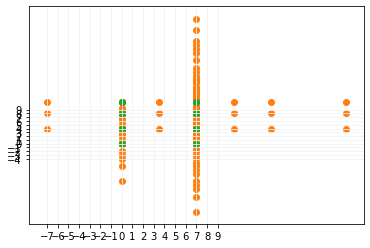

In [11]:
fig = plt.figure()
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2')
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

In [12]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((7,0), 0)
c3 = mod.critical_val((0,4),0)
c4 = mod.critical_val((7,4),0)
c5 = mod.critical_val((0,7),0)
c6 = mod.critical_val((7,7),0)
c7 = mod.critical_val((0,11),0)
c8 = mod.critical_val((7,11),0)


d1 = mod.critical_val((0,0), 1)
d2 = mod.critical_val((7,0), 1)
d3 = mod.critical_val((0,4),1)
d4 = mod.critical_val((7,4),1)
d5 = mod.critical_val((0,7),1)
d6 = mod.critical_val((7,7),1)
d7 = mod.critical_val((0,11),1)
d8 = mod.critical_val((7,11),1)

CritPts = [c1,c2,c3,c4,c5,c6,c7,c8,d1,d2,d3,d4,d5,d6,d7,d8]



In [13]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]


for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
                    Dict_pts += dict_pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

with open('ExamplePaper-2_11.csv', 'a', newline='') as file:  
    writer = csv.writer(file)
    writer.writerows(Dict_pts)                    
            


                    

The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module o

Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (7, 3.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 7) is 0)
v = (parent module of (7, 4) is 0)
****************
The omega point (7, -3.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module of (7, 7) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 3.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 7) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (7, 7.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 11) is 0)
v = (parent module of (7, 4) is 0)
****************
The omega point (7, -7.0) was generated from
x = (parent module of (7,

Computed 9 omega points with duplicates
Without duplicates: 8
The omega point (7, 6.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 7) is 0)
v = (parent module of (7, 4) is 1)
****************
The omega point (7, 15.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 7) is 0)
u = (parent module of (7, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.5) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 1)
u = (parent module of (0, 7) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 9
The omega point (7, 21.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 7) is 0)
u = (parent module of (0, 7) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 10.5) was generated from
x = (parent module of (7,

The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 11) is 0)
v = (parent module of (0, 11) is 0)
****************
The omega point (7, 22.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 11) is 0)
u = (parent module of (7, 11) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 11) is 0)
u = (parent module of (0, 11) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 8 omega points with duplicates
Without duplicates: 4
The omega point (7, 22.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 11) is 0)
v = (parent module of (0, 0) is 1)
****************
The omega point (7, 5.5) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 1)
u = (parent

The omega point (7, -3.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 11) is 0)
u = (parent module of (7, 7) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 1.5) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 7) is 1)
u = (parent module of (7, 11) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 7
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 11) is 1)
v = (parent module of (7, 11) is 0)
****************
The omega point (7, -11.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 11) is 0)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 16.5) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 11) is 1)
u = (pare

...

The omega point (7, 4.0) was generated from
x = (parent module of (7, 11) is 1)
w = (parent module of (0, 0) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 7) is 1)
****************
The omega point (7, 18.0) was generated from
x = (parent module of (7, 11) is 1)
w = (parent module of (0, 7) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 0) is 1)
****************
The omega point (7, 18.0) was generated from
x = (parent module of (7, 11) is 1)
w = (parent module of (0, 11) is 1)
u = (parent module of (0, 7) is 1)
v = (parent module of (0, 0) is 1)
****************
Computed 9 omega points with duplicates
Without duplicates: 4
The omega point (0, 7.0) was generated from
x = (parent module of (0, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 7) is 1)
****************
The omega point (0, 7.0) was generated from
x = (parent module of (0, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (pare

Computed 12 omega points with duplicates
Without duplicates: 6
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 7) is 1)
u = (parent module of (7, 7) is 1)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 7) is 1)
u = (parent module of (7, 7) is 1)
v = (parent module of (0, 4) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 1
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (0, 4) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (7, 7) is 1)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 7) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 14.0) was generated from
x = (parent module of (7

Computed 9 omega points with duplicates
Without duplicates: 3
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 4) is 1)
****************
The omega point (7, 4.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 4) is 1)
****************
Computed 2 omega points with duplicates
Without duplicates: 1
The omega point (7, 7.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 7) is 1)
u = (parent module of (7, 7) is 1)
v = (parent module of (0, 7) is 1)
****************
The omega point (7, 7.0) was generated from
x = (parent module of (7, 0) is 1)
w = (parent module of (7, 7) is 1)
u = (parent module of (7, 7) is 1)
v = (parent module of (0, 7) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 1
The om

The omega point (7, 8.0) was generated from
x = (parent module of (7, 4) is 1)
w = (parent module of (0, 4) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (7, 7) is 1)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 4) is 1)
w = (parent module of (7, 7) is 1)
u = (parent module of (0, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 14.0) was generated from
x = (parent module of (7, 4) is 1)
w = (parent module of (0, 11) is 1)
u = (parent module of (7, 7) is 1)
v = (parent module of (0, 4) is 1)
****************
Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (7, 8.0) was generated from
x = (parent module of (7, 4) is 1)
w = (parent module of (0, 4) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 7) is 1)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 4) is 1)
w = (parent module of (7, 7) is 1)
u = (parent mod

Computed 11 omega points with duplicates
Without duplicates: 5
The omega point (0, 7.0) was generated from
x = (parent module of (0, 4) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 7) is 1)
****************
The omega point (0, 7.0) was generated from
x = (parent module of (0, 4) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (7, 7) is 1)
****************
The omega point (7, 4.0) was generated from
x = (parent module of (7, 7) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
The omega point (7, 4.0) was generated from
x = (parent module of (7, 7) is 1)
w = (parent module of (7, 11) is 1)
u = (parent module of (7, 11) is 1)
v = (parent module of (0, 4) is 1)
****************
Computed 6 omega points with duplicates
Without duplicates: 2
The omega point (0, 11.0) was generated from
x = (parent module

In [14]:
print(Pts)

[(7, 3.0), (7, 3.5), (7, 12.0), (14.0, 4), (7, 12.5), (0.0, 7), (7, 25.0), (0, 7.5), (7, -15.0), (3.5, 7), (10.5, 7), (7, 6.0), (7, 19.0), (0.0, 4), (7, 5.0), (7, 5.5), (7, 22.0), (0, -3.0), (0, 1.0), (7, -18.0), (7, 8.0), (7, 8.5), (7, 21.0), (3.5, 11), (7, -1.0), (7, -2.0), (7, 2.0), (7, 2.5), (7, 15.0), (0.0, 11), (7, -3.0), (10.5, 4), (7, 1.5), (7, 1.0), (7, 18.0), (0, 5.5), (0, 5.0), (21.0, 11), (0, 8.0), (7, 4.0), (7, 17.0), (0, -1.0), (0, -2.0), (0, 2.0), (0, 2.5), (-7.0, 4), (7, 11.0), (7, 33.0), (7, -7.0), (-7.0, 7), (7, 14.0), (7, 14.5), (21.0, 4), (7, -4.0), (7, 0.0), (7, 0.5), (7, 13.0), (14.0, 7), (0, 9.5), (0, 9.0), (7, -10.0), (21.0, 7), (3.5, 4), (10.5, 11), (7.0, 7), (7, 7.5), (7, 16.5), (0, 3.5), (7, 29.0), (0, 3.0), (-7.0, 11), (7, -11.0), (7, 10.5), (7, 10.0), (0, -4.0), (0, 0.0), (0, 0.5), (7, 9.0), (14.0, 11), (7, 9.5), (0, -10.0), (7, 26.0), (0, -7.0), (7, -1.5)]


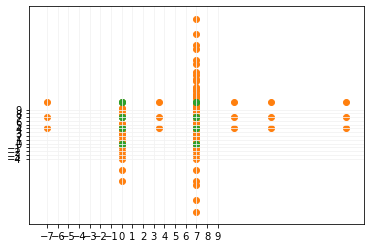

In [15]:
fig = plt.figure()
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2')
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

### Example 1
$M=[0,7]x[0,8]$ and $N=[1,8]x[1,9]$

In [16]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((7,0), 0)
c3 = mod.critical_val((0,8),0)
c4 = mod.critical_val((7,8),0)



d1 = mod.critical_val((1,1), 1)
d2 = mod.critical_val((8,1), 1)
d3 = mod.critical_val((1,9),1)
d4 = mod.critical_val((8,9),1)


CritPts = [c1,c2,c3,c4,d1,d2,d3,d4]



In [17]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]


for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
                    Dict_pts += dict_pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))
with open('ExampleNotebook-1.csv', 'a', newline='') as file:  
    writer = csv.writer(file)
    writer.writerows(Dict_pts)                    
            


                    

The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (0, 8) is 0)
****************
The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 8) is 0)
u = (parent modul

Computed 6 omega points with duplicates
Without duplicates: 3
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (8, 1) is 1)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 2.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 1) is 1)
u = (parent module of (8, 1) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (8, 1) is 1)
u = (parent module of (1, 1) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (8, 1.0) was generated from
x = (parent module of (8, 1) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module of (1, 1) is 1)
v = (parent module of (7, 0) is 0)
****************
The omega point (8, 1.0) was generated from
x = (parent module of (8, 1) is 1)
w = (parent module of (7, 0) is 0)
u = (parent module o

The omega point (7, 14.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 10.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (1, 1) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 5.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (1, 1) is 1)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (1, 0.0) was generated from
x = (parent module of (1, 1) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (0, 8) is 0)
****************
The omega point (1, 12.0) was generated from
x = (parent module of (1, 1) is 1)
w = (parent module of (0, 8) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (0, 0) is 0)
*********

The omega point (8, 17.0) was generated from
x = (parent module of (8, 1) is 1)
w = (parent module of (1, 9) is 1)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 16 omega points with duplicates
Without duplicates: 9
The omega point (0, 0.0) was generated from
x = (parent module of (0, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (8, 9) is 1)
v = (parent module of (8, 1) is 1)
****************
The omega point (0, 0.0) was generated from
x = (parent module of (0, 0) is 0)
w = (parent module of (8, 1) is 1)
u = (parent module of (8, 9) is 1)
v = (parent module of (0, 8) is 0)
****************
The omega point (0, 2.0) was generated from
x = (parent module of (0, 0) is 0)
w = (parent module of (8, 9) is 1)
u = (parent module of (0, 8) is 0)
v = (parent module of (8, 1) is 1)
****************
The omega point (8, 1.0) was generated from
x = (parent module of (8, 1) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module

The omega point (8, 7.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
The omega point (8, 9.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (7, 8) is 0)
u = (parent module of (1, 1) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (8, 9.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (1, 1) is 1)
u = (parent module of (7, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 18 omega points with duplicates
Without duplicates: 10
The omega point (0, -6.0) was generated from
x = (parent module of (0, 0) is 0)
w = (parent module of (8, 1) is 1)
u = (parent module of (7, 8) is 0)
v = (parent module of (8, 1) is 1)
****************
The omega point (0, -6.0) was generated from
x = (parent module of (0, 0) is 0)
w = (parent module of (8, 1) is 1)
u = (parent modu

...

The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (0, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
Computed 15 omega points with duplicates
Without duplicates: 7
The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (8, 9) is 1)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 2.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 1) is 1)
u = (parent module of (8, 9) is 1)
v = (parent module of (0, 8) is 0)
****************
The omega point (7, 2.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (8, 9) is 1)
u = (parent module of (0, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
The omega point (8, 7.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (7, 0) is 0)
u = (parent modul

The omega point (8, 7.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (7, 0) is 0)
u = (parent module of (7, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
The omega point (8, 9.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (7, 8) is 0)
u = (parent module of (1, 1) is 1)
v = (parent module of (7, 0) is 0)
****************
The omega point (8, 9.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (1, 1) is 1)
u = (parent module of (7, 8) is 0)
v = (parent module of (7, 0) is 0)
****************
Computed 17 omega points with duplicates
Without duplicates: 10
The omega point (7, -6.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (8, 1) is 1)
u = (parent module of (7, 8) is 0)
v = (parent module of (8, 1) is 1)
****************
The omega point (7, -6.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (8, 1) is 1)
u = (parent modu

Computed 14 omega points with duplicates
Without duplicates: 11
The omega point (7, 13.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (1, 9) is 1)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 13.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (1, 9) is 1)
v = (parent module of (1, 1) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (7, 1.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 1) is 1)
u = (parent module of (8, 9) is 1)
v = (parent module of (1, 9) is 1)
****************
The omega point (7, 13.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (8, 9) is 1)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 5.0) was generated from
x = (parent module of (

The omega point (7, 8.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (8, 9) is 1)
v = (parent module of (1, 9) is 1)
****************
The omega point (7, 10.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (8, 9) is 1)
v = (parent module of (0, 8) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (8, 9) is 1)
u = (parent module of (1, 9) is 1)
v = (parent module of (0, 8) is 0)
****************
The omega point (8, 9.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (0, 8) is 0)
u = (parent module of (1, 9) is 1)
v = (parent module of (7, 8) is 0)
****************
The omega point (8, 9.0) was generated from
x = (parent module of (8, 9) is 1)
w = (parent module of (7, 8) is 0)
u = (parent module of (1, 9) is 1)
v = (parent module of (0, 8) is 0)
***********

The omega point (8, -5.0) was generated from
x = (parent module of (8, 1) is 1)
w = (parent module of (8, 9) is 1)
u = (parent module of (7, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
Computed 14 omega points with duplicates
Without duplicates: 12
The omega point (7, 13.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (1, 9) is 1)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 13.0) was generated from
x = (parent module of (7, 8) is 0)
w = (parent module of (1, 9) is 1)
u = (parent module of (1, 9) is 1)
v = (parent module of (1, 1) is 1)
****************
The omega point (1, 7.0) was generated from
x = (parent module of (1, 1) is 1)
w = (parent module of (1, 9) is 1)
u = (parent module of (1, 9) is 1)
v = (parent module of (7, 8) is 0)
****************
The omega point (1, 7.0) was generated from
x = (parent module of (1, 1) is 1)
w = (parent module of (1, 9) is 1)
u = (parent mod

In [18]:
print(Pts)

[(6.0, 9), (-2.5, 0), (1, 17.0), (15.0, 1), (-8.0, 1), (5.0, 8), (4.5, 0), (7, 6.0), (20.0, 9), (1.0, 1), (8, 15.0), (7, 5.0), (7, 22.0), (0, -3.0), (0, 1.0), (1, 12.0), (8, 12.0), (7, 8.0), (14.0, 8), (12.0, 8), (19.0, 8), (0, -6.0), (8.0, 9), (7, 2.0), (-1.0, 1), (7, -3.0), (10.5, 9), (10.0, 9), (-5.0, 0), (7, 1.0), (7, 18.0), (0, 5.0), (1.0, 0), (0.0, 8), (8, 3.0), (6.0, 1), (-9.0, 8), (-2.5, 8), (15.0, 9), (13.0, 9), (0, 2.0), (-8.0, 9), (7, -6.0), (4.5, 8), (2.0, 8), (9.0, 8), (8.0, 0), (23.0, 8), (8, 19.0), (1, -1.0), (24.0, 9), (5.0, 0), (7, 14.0), (1, 4.0), (3.5, 9), (3.0, 9), (1.0, 9), (8, 7.0), (7, 0.0), (8, -9.0), (1, -9.0), (11.5, 8), (7, 13.0), (16.0, 8), (0, 6.0), (1, 7.0), (0.0, 9), (-7.0, 8), (7, -10.0), (8, 4.0), (8, 23.0), (-1.0, 9), (-4.0, 9), (7, 16.0), (8, 1.0), (8, -1.0), (7, 10.0), (0.0, 0), (8, 11.0), (7, -8.0), (8, 17.0), (-5.0, 8), (8, -5.0), (7.0, 9), (17.0, 9), (7, 26.0), (2.0, 0), (1.0, 8), (8, 8.0), (8, 27.0)]


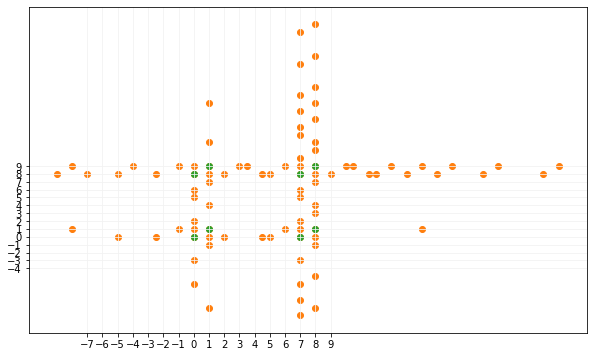

In [19]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2')
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

### Example 2 
$M=[0,4]x[0,4]$ and $N=[1,3]x[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

In [20]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((4,0), 0)
c3 = mod.critical_val((0,4),0)
c4 = mod.critical_val((4,4),0)

d1 = mod.critical_val((1,0), 1)
d2 = mod.critical_val((3,0), 1)
d3 = mod.critical_val((1,4),1)
d4 = mod.critical_val((3,4),1)

CritPts = [c1,c2,c3,c4,d1,d2,d3,d4]

In [21]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]


for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
                    Dict_pts += dict_pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))
with open('ExampleNotebook-2.csv', 'a', newline='') as file:  
    writer = csv.writer(file)
    writer.writerows(Dict_pts)                    
            

The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (4, 0.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (4, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (4, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 0.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (4, 4) is 0)
u = (parent module o

Computed 11 omega points with duplicates
Without duplicates: 5
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
Computed 6 omega points with duplicates
Without duplicates: 3
The omega point (4, 0.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (3, 4) is 1)
v = (parent module of (1, 4) is 1)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 4) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0

The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 4) is 0)
****************
The omega point (3, 8.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (3, 8.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (1, 4) is 1)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 5
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module of (3, 4) is 1)
v = (parent module of (0, 4) is 0)
****************
The omega point (3, 8.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (0, 4) is 0)
u = (parent module o

The omega point (4, 4.0) was generated from
x = (parent module of (4, 4) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (3, 4) is 1)
v = (parent module of (3, 0) is 1)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 4) is 0)
w = (parent module of (3, 0) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 4) is 0)
w = (parent module of (3, 4) is 1)
u = (parent module of (3, 0) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (0, 0) is 0)
u = (parent module of (3, 4) is 1)
v = (parent module of (4, 4) is 0)
****************
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (4, 4) is 0)
u = (parent module of (3, 4) is 1)
v = (parent module of (0, 0) is 0)
************

Computed 9 omega points with duplicates
Without duplicates: 6
The omega point (4, 12.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (4, 4) is 0)
v = (parent module of (3, 0) is 1)
****************
The omega point (4, -4.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (4, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (3, 0) is 1)
****************
The omega point (4, 0.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (3, 0) is 1)
u = (parent module of (4, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
Computed 9 omega points with duplicates
Without duplicates: 6
The omega point (4, 4.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 4) is 1)
v = (parent module of (4, 4) is 0)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 

Computed 8 omega points with duplicates
Without duplicates: 4
The omega point (4, 0.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (4, 4) is 0)
u = (parent module of (3, 4) is 1)
v = (parent module of (1, 0) is 1)
****************
The omega point (4, 0.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 0) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (4, 4) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (3, 4) is 1)
u = (parent module of (4, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
Computed 11 omega points with duplicates
Without duplicates: 5
The omega point (4, 4.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (3, 0) is 1)
u = (parent module of (4, 4) is 0)
v = (parent module of (3, 0) is 1)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 0

The omega point (3, 8.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (0, 4) is 0)
u = (parent module of (4, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (4, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (1, 0) is 1)
u = (parent module of (4, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
Computed 12 omega points with duplicates
Without duplicates: 6
The omega point (4, 8.0) was generated from
x = (parent module of (4, 4) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 4) is 1)
v = (parent module of (1, 0) is 1)
****************
The omega point (4, 0.0) was generated from
x = (parent module of (4, 4) is 0)
w = (parent module of (1, 0) is 1)
u = (parent module 

The omega point (1, 4.0) was generated from
x = (parent module of (1, 0) is 1)
w = (parent module of (3, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 4) is 0)
****************
The omega point (3, 6.0) was generated from
x = (parent module of (3, 4) is 1)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 4) is 1)
v = (parent module of (1, 0) is 1)
****************
The omega point (3, 0.0) was generated from
x = (parent module of (3, 4) is 1)
w = (parent module of (1, 0) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 4) is 0)
****************
The omega point (3, 12.0) was generated from
x = (parent module of (3, 4) is 1)
w = (parent module of (1, 4) is 1)
u = (parent module of (0, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
Computed 11 omega points with duplicates
Without duplicates: 7
The omega point (1, 4.0) was generated from
x = (parent module of (1, 0) is 1)
w = (parent module of (3, 4) is 1)
u = (parent module

Computed 8 omega points with duplicates
Without duplicates: 4
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (3, 4) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (1, 0) is 1)
****************
The omega point (3, 0.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (3, 4) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (1, 0) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 1
The omega point (1, 4.0) was generated from
x = (parent module of (1, 0) is 1)
w = (parent module of (3, 4) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (1, 4) is 1)
****************
The omega point (1, 4.0) was generated from
x = (parent module of (1, 0) is 1)
w = (parent module of (3, 4) is 1)
u = (parent module of (3, 4) is 1)
v = (parent module of (1, 4) is 1)
****************
Computed 4 omega points with duplicates
Without duplicates: 1
The omega 

In [22]:
print(Pts)

[(-1.0, 4), (-2.0, 0), (4, 8.0), (3.0, 0), (4, 12.0), (1, 6.0), (9.0, 4), (4, 0.0), (1, 2.0), (4, 4.0), (3, -4.0), (3, 6.0), (0.0, 4), (6.0, 4), (5.0, 4), (0.0, 0), (3, 2.0), (10.0, 4), (1.0, 4), (1, -4.0), (4, 2.0), (1.0, 0), (4, -4.0), (3, 12.0), (4, 6.0), (7.0, 4), (2.0, 0), (1, 8.0), (3, 8.0), (-2.0, 4), (-3.0, 4), (3.0, 4), (2.0, 4), (8.0, 4)]


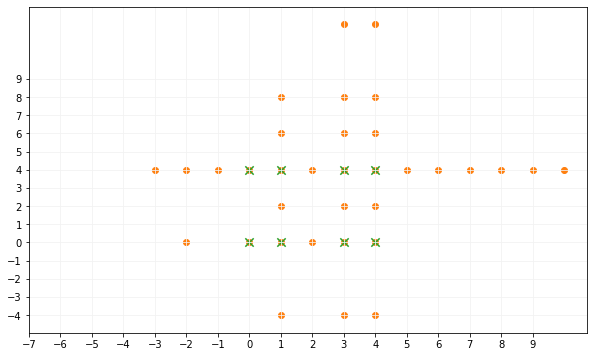

In [23]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2', marker = "x", s=70)
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

###### remark: in this example we should not need the omega pts on the boundary of the support 

### without the closure 
in the examples above we ran the algorithm on $\overline{C_M}\sqcup\overline{C_N}$, here we try the last example above with $C_M\sqcup C_N$

In [24]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((4,0), 0)
c3 = mod.critical_val((0,4),0)

d1 = mod.critical_val((1,0), 1)
d2 = mod.critical_val((3,0), 1)
d3 = mod.critical_val((1,4),1)

CritPts = [c1,c2,c3,d1,d2,d3]

In [25]:
Pts =[]

for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 0) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 2.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 0) is 1)
u = (parent module o

Computed 11 omega points with duplicates
Without duplicates: 8
The omega point (1, -4.0) was generated from
x = (parent module of (1, 0) is 1)
w = (parent module of (1, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (1, -4.0) was generated from
x = (parent module of (1, 0) is 1)
w = (parent module of (1, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
Computed 4 omega points with duplicates
Without duplicates: 2
The omega point (3, 12.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (1, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (3, 12.0) was generated from
x = (parent module of (3, 0) is 1)
w = (parent module of (1, 4) is 1)
u = (parent module of (1, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
Computed 6 omega points with duplicates
Without duplicates: 3
The o

TypeError: unhashable type: 'list'

In [ ]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2', marker = "x", s=70)
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

## Todo: 
- print out vaalue of eta and delta when printing the omegapts and the critical points it comes from
- add something to know when it was computed in terms of line of code

## Further analysis: 
    2. Can we determine which ones are usless
    3. compute distance and see which $\Omega$-pts are interesting --> we also dont have ALL the $\Omega$-pts because we only implemented one part of the entire algo to compute the 3vs1 case and not the 2v2 cases

### IDEA: 

    omega-pts are center of symetries for bars hence they need to be in the support of the module 